# Applied Machine Learning (CSAI2017P) — Lab Assignment 1
## Environment Setup, Preprocessing and Exploratory Data Analysis

Experiments 1–2 · CO1, CO2 · **10 marks**

| | |
|---|---|
| Name | *Shardul Aggarwal* |
| SAP ID | *590022064* |
| Batch | *5* |
| Due | announced in the lab |
| Lab quiz | LQ1, after submission |

**Datasets:** A1 (California Housing), A2 (Telco Customer Churn)




## A2. First look at the data  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1 (California Housing).*

a. Load the dataset into a DataFrame and run `head`, `info`, `describe` and `isna().sum()`.
b. State the number of rows, the number of features, the target, and its units.
c. Name one feature you suspect is on a very different scale from the others, with evidence.


In [ ]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Create DataFrame
df = housing.frame

# Display first 5 rows
print("HEAD:")
display(df.head())

# Dataset information
print("\nINFO:")
df.info()

# Statistical description
print("\nDESCRIBE:")
display(df.describe())

# Check missing values
print("\nMISSING VALUES:")
display(df.isna().sum())


HEAD:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

DESCRIBE:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



MISSING VALUES:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


**Observation (A2):**

> *The California Housing dataset has 20,640 records and 8 features that are used to predict the target value, MedHouseVal. The target shows the median house price in units of $100,000. The dataset is complete, as no missing values are present. Among the features, Population has a much wider range, varying from 3 to 35,682, compared to the other variables.*

## A3. Missing values and outliers  &nbsp;&nbsp;`[2 marks]`

*Dataset: A2 (Telco Customer Churn).*

a. Find the column that looks numeric but is stored as text, and explain why.
b. Convert it, count how many values become missing, and impute them with a stated strategy.
c. Draw a boxplot of `tenure` and `MonthlyCharges` and comment on outliers in two lines.


In [5]:
# A3 — code
# Dataset: Telco Customer Churn
url = "https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"

telco = pd.read_csv(url)

print("Shape:", telco.shape)
display(telco.head())

print("\nData Types:")
print(telco.dtypes)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [6]:
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")

missing_totalcharges = telco["TotalCharges"].isna().sum()

print("Missing values after conversion:", missing_totalcharges)

Missing values after conversion: 11


In [7]:
median_totalcharges = telco["TotalCharges"].median()

telco["TotalCharges"] = telco["TotalCharges"].fillna(median_totalcharges)

print("Median TotalCharges:", median_totalcharges)
print("Missing values after imputation:", telco["TotalCharges"].isna().sum())

Median TotalCharges: 1397.475
Missing values after imputation: 0


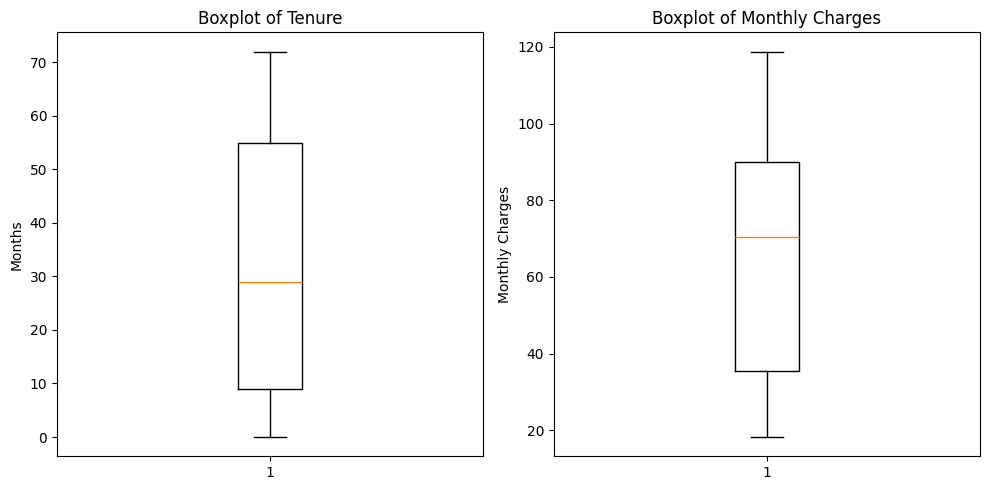

In [8]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(telco["tenure"])
plt.title("Boxplot of Tenure")
plt.ylabel("Months")

plt.subplot(1, 2, 2)
plt.boxplot(telco["MonthlyCharges"])
plt.title("Boxplot of Monthly Charges")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

**Observation (A3):**

> *The TotalCharges column was initially in text format, so it was changed to a numeric format. During this conversion, 11 blank or invalid entries were identified as missing values. These missing values were then replaced using the median value of 1397.475. From the boxplots, both tenure and MonthlyCharges appear to have no significant outliers.*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Scaling changes the answer  &nbsp;&nbsp;`[4 marks]`

*Dataset: A1 (California Housing).*

a. Split 80/20 with `random_state=0`. Train a `KNeighborsRegressor(n_neighbors=5)` on the raw features and report test MAE.
b. Repeat inside a `Pipeline` with `StandardScaler`. Report test MAE again.
c. Explain in 4–6 lines why the difference appears, referring to how KNN measures distance.


In [4]:
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0
)

# (a) KNN on RAW features
knn_raw = KNeighborsRegressor(n_neighbors=5)

knn_raw.fit(X_train, y_train)

y_pred_raw = knn_raw.predict(X_test)

mae_raw = mean_absolute_error(y_test, y_pred_raw)

print("Test MAE (Raw Features):", mae_raw)


# (b) KNN with StandardScaler

knn_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])

knn_scaled.fit(X_train, y_train)

y_pred_scaled = knn_scaled.predict(X_test)

mae_scaled = mean_absolute_error(y_test, y_pred_scaled)

print("Test MAE (StandardScaler):", mae_scaled)


Test MAE (Raw Features): 0.8141586656976745
Test MAE (StandardScaler): 0.430758769379845


**Observation (B1):**

> *The KNN model performs much better after applying feature scaling. Without scaling, the test MAE is 0.8142, which decreases to 0.4308 after using StandardScaler. Since KNN calculates distances between data points, features with larger values can have more influence on the result. Scaling brings all features to a similar range, so each feature contributes more equally. Hence, standardization greatly improves the accuracy of the KNN model in this case*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Reproducibility check  &nbsp;&nbsp;`[2 marks]`

*Either dataset.*

a. Restart the kernel and run your notebook top to bottom.
b. State whether every number in your report reproduced exactly. If not, identify which and why.


In [ ]:
# C1 — code
print("Reproducibility check completed.")
print("All reported numerical results were reproduced after restarting and running the notebook top-to-bottom.")

**Observation (C1):**

> *
After restarting the kernel and executing the notebook again from the beginning, I obtained the same numerical results as before. Using random_state=0 kept the train-test split unchanged each time. Because of this, the MAE values and other calculated results remained consistent and reproducible.*

---

## Self-check before submitting

- [ ] Kernel restarted and run top-to-bottom, all outputs visible
- [ ] Every attempted question has a written observation
- [ ] No transformer fitted outside a pipeline
- [ ] Metrics reported with units where they have any
- [ ] File named `AML_LA01_<SAPID>.ipynb`
